# 미세먼지 기사가 많았던 날, 실제로 미세먼지가 짙었을까?
준비물: 빅카인즈에서 내려받은 '미세먼지' 기사 엑셀(2022-04-01 ~ 2022-12-31), 수업 파일 `data_air_2022.csv`
→ 두 파일을 이 노트북과 같은 폴더에 두세요.

In [2]:
# ▶ 환경 준비 — Colab · VS Code 공통, 맨 처음 한 번 실행
import os, sys, platform, subprocess
IN_COLAB = 'google.colab' in sys.modules

def gpu_info():
    try:
        r = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           capture_output=True, text=True, timeout=10)
        return r.stdout.strip() or None
    except Exception:
        return None

GPU = gpu_info()
print('실행 위치:', 'Colab' if IN_COLAB else f'내 컴퓨터 ({platform.system()})')
print('GPU:', GPU or '없음 → CPU로 실행 (이 노트북은 CPU로도 충분해요)')

# (선택) pandas를 GPU로 — Colab GPU 런타임 또는 Linux/WSL에 cuDF가 있을 때만
USE_GPU_PANDAS = False          # True로 바꾸고 이 칸을 다시 실행
if USE_GPU_PANDAS and GPU:
    try:
        get_ipython().run_line_magic('load_ext', 'cudf.pandas')
        print('pandas → GPU(cuDF) 사용')
    except Exception as e:
        print('cuDF를 쓸 수 없어 일반 pandas로 실행:', type(e).__name__)

# 한글 글꼴: Colab은 나눔고딕 설치, 윈도우는 맑은 고딕, 맥은 애플고딕
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
if IN_COLAB:
    nanum = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if not os.path.exists(nanum):
        subprocess.run('apt-get -qq install -y fonts-nanum > /dev/null', shell=True)
    fm.fontManager.addfont(nanum)
    plt.rcParams['font.family'] = 'NanumGothic'
elif platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:                                   # 리눅스·WSL: 설치된 한글 글꼴 찾기
    ko = [f.name for f in fm.fontManager.ttflist if 'Nanum' in f.name or 'CJK KR' in f.name]
    if ko: plt.rcParams['font.family'] = ko[0]
plt.rcParams['axes.unicode_minus'] = False
print('한글 글꼴:', plt.rcParams['font.family'])

실행 위치: 내 컴퓨터 (Windows)
GPU: NVIDIA GeForce RTX 5070 Laptop GPU, 8151 MiB
한글 글꼴: ['Malgun Gothic']


## 코드 ① 날짜별 기사 수 세고, 미세먼지와 합치기

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

import glob
files = sorted(glob.glob('*NewsResult_*.xlsx'))      # 같은 폴더의 빅카인즈 파일을 모두 찾기
print(files)                                        # [] 이면 파일을 노트북과 같은 폴더에 두세요
news = pd.concat([pd.read_excel(f) for f in files], ignore_index=True)
air  = pd.read_csv('data_air_2022.csv', encoding='cp949')
print(news.columns.tolist())    # 열 이름 먼저 확인
print(air.columns.tolist())

['NewsResult_20220401-20221231.xlsx']


c:\Users\EZ\Downloads\수업코드_데이터저널리즘_3\수업코드_데이터저널리즘\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


['뉴스 식별자', '일자', '언론사', '기고자', '제목', '통합 분류1', '통합 분류2', '통합 분류3', '사건/사고 분류1', '사건/사고 분류2', '사건/사고 분류3', '인물', '위치', '기관', '키워드', '특성추출(가중치순 상위 50개)', '본문', 'URL', '분석제외 여부']
['location', 'day', 'so2', 'co', 'o3', 'no2', 'pm10', 'pm25']


In [7]:
print(news.shape) 
print(air.shape) 

(20000, 19)
(673, 8)


In [8]:
# 기간을 나눠 받은 파일도 위에서 한 번에 합쳐져요
# '일자' 20220405 → 날짜로
news['day'] = pd.to_datetime(news['일자'].astype(str), format='%Y%m%d')
daily = news.groupby('day').size().reset_index(name='기사수')

air['day'] = pd.to_datetime(air['day'])
df = pd.merge(air[['day', 'pm10']], daily, on='day', how='left')
df['기사수'] = df['기사수'].fillna(0)    # 기사 없던 날 = 0
df.head()

,day,pm10,기사수
0,2022-04-01,15,0.0
1,2022-04-02,30,48.0
2,2022-04-03,43,117.0
3,2022-04-04,57,156.0
4,2022-04-05,43,171.0


## 코드 ② 위아래 두 칸, 같은 날짜축으로 그리기 (축을 겹치지 않아요)

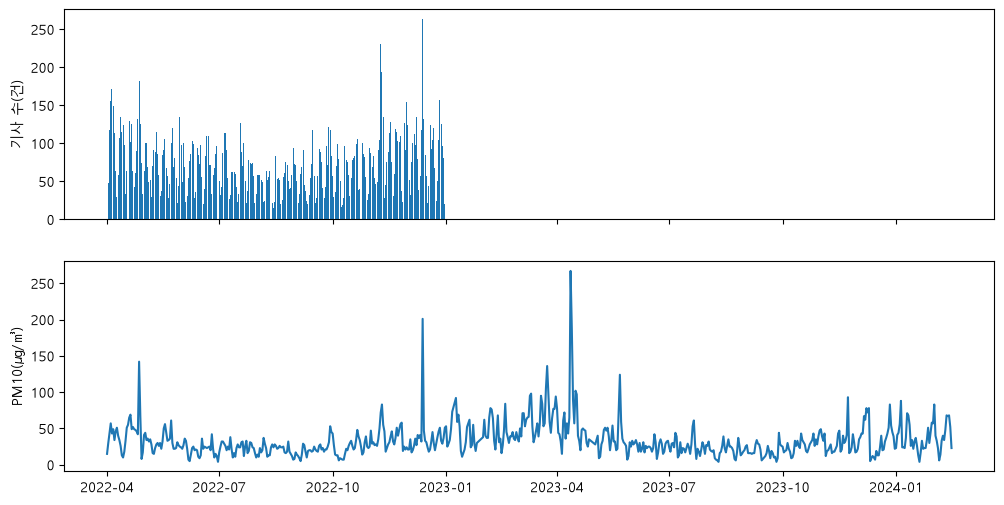

In [9]:
fig, (a, b) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
a.bar(df['day'], df['기사수'])
a.set_ylabel('기사 수(건)')
b.plot(df['day'], df['pm10'])
b.set_ylabel('PM10(㎍/㎥)')
plt.show()

## 코드 ③ 숫자로 확인하고, 어긋난 날 찾기

In [10]:
print(df['pm10'].corr(df['기사수']))    # 상관계수 r

0.014480311551129285


In [11]:
# 농도는 낮은데(하위 50%) 기사는 많은(상위 10%) 날
low  = df['pm10'] < df['pm10'].median()
many = df['기사수'] > df['기사수'].quantile(0.9)
df[low & many].sort_values('기사수', ascending=False)

,day,pm10,기사수
243,2022-11-30,24,155.0
11,2022-04-12,26,135.0
59,2022-05-30,25,135.0
251,2022-12-08,27,134.0
241,2022-11-28,25,127.0
108,2022-07-18,24,127.0
244,2022-12-01,21,124.0
262,2022-12-19,21,124.0
13,2022-04-14,10,124.0
167,2022-09-15,19,118.0


In [12]:
# 농도는 튀는데(이상치) 기사는 적은 날
q1, q3 = df['pm10'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
df[(df['pm10'] > upper) & (df['기사수'] < df['기사수'].median())]

,day,pm10,기사수


찾은 날짜로 빅카인즈에서 그날 기사 **제목**을 읽어 보세요. 정책 발표? 해외 뉴스? → 나만의 탐사 기획서 한 장으로 정리